In [3]:
import pandas as pd
import numpy as np
from pprint import pprint
from glob import glob
import os
import matplotlib.pyplot as plt
from IPython.display import display

In [4]:
def get_topk_dict(df, ks, metric):
    topk_d = {}
    for k in ks:
        topk_d[k] = (df[f"{metric}_rank"] <= k).mean().item()
    return topk_d

def get_rank_dict(df, ks, metric):
    rank_d = {}
    for k in ks:
        rank_d[k] = (df[f"{metric}_rank"] == k).mean().item()
        # rank_d[k] = (df[f"{metric}_rank"] == k).sum().item()
    return rank_d

def get_all_topk_df(root_dp, models, model_to_metric, num_seeds, ks):

    model_topk_ds = []
    for model in models:
        seed_topk_ds = []
        for seed in range(num_seeds):
            fp = os.path.join(root_dp, f"{model}_s{seed}_summary.csv")
            df = pd.read_csv(fp)
            topk_d = get_topk_dict(df, ks, model_to_metric[model])
            topk_d["model"] = model
            seed_topk_ds.append(topk_d)
        model_topk_d = {}
        for k in ks:
            for seed in range(num_seeds):
                model_topk_d[k] = model_topk_d.get(k, 0) + seed_topk_ds[seed][k]
            model_topk_d[k] /= num_seeds
        model_topk_d["model"] = model
        model_topk_ds.append(model_topk_d)        
    model_topk_ds.append({"model":"random", **{k:k/len(ks) for k in ks}})
    topk_df = pd.DataFrame(model_topk_ds)
    return topk_df

def get_all_rank_df(root_dp, models, model_to_metric, num_seeds, ks):

    model_rank_ds = []
    for model in models:
        seed_rank_ds = []
        for seed in range(num_seeds):
            fp = os.path.join(root_dp, f"{model}_s{seed}_summary.csv")
            df = pd.read_csv(fp)
            rank_d = get_rank_dict(df, ks, model_to_metric[model])
            rank_d["model"] = model
            seed_rank_ds.append(rank_d)
        model_rank_d = {}
        for k in ks:
            for seed in range(num_seeds):
                model_rank_d[k] = model_rank_d.get(k, 0) + seed_rank_ds[seed][k]
            model_rank_d[k] /= num_seeds
        model_rank_d["model"] = model
        model_rank_ds.append(model_rank_d)        
    model_rank_ds.append({"model":"random", **{k:1/len(ks) for k in ks}})
    rank_df = pd.DataFrame(model_rank_ds)
    return rank_df

In [5]:
pubchem_retrieval_dp = "../data/ms2c/pubchem/benchmark"
inchikey_dp = os.path.join(pubchem_retrieval_dp, "ms2pubchem_nist20mona23v3_d4_wr00_inchikey_test_10ppm_MORGAN-R2_50")
scaffold_dp = os.path.join(pubchem_retrieval_dp, "ms2pubchem_nist20mona23v3_d4_wr00_scaffold_test_10ppm_MORGAN-R2_50")
# inchikey_df = pd.read_csv(inchikey_fp)
# scaffold_df = pd.read_csv(scaffold_fp)

In [6]:
num_seeds = 5
ks = list(range(1,51))
model_to_label = {
    "neims_long": "NEIMS",
    "massformer_long": "MassFormer",
    "iceberg_inten3_100_long": "ICEBERG",
    "fraggnn_d4_long": "FraGNNet-D4"
}
models = list(model_to_label.keys())
model_to_metric = {
    "neims_long": "cos_sim_0.01",
    "massformer_long": "cos_sim_0.01",
    "iceberg_inten3_100_long": "cos_sim_0.01",
    "fraggnn_d4_long": "cos_hun"
}

inchikey_topk_df = get_all_topk_df(inchikey_dp, models, model_to_metric, num_seeds, ks)
scaffold_topk_df = get_all_topk_df(scaffold_dp, models, model_to_metric, num_seeds, ks)
inchikey_rank_df = get_all_rank_df(inchikey_dp, models, model_to_metric, num_seeds, ks)
scaffold_rank_df = get_all_rank_df(scaffold_dp, models, model_to_metric, num_seeds, ks)

In [7]:
# print(scaffold_topk_df[scaffold_topk_df["model"] == "neims_long"].columns)
# print(scaffold_topk_df[scaffold_topk_df["model"] == "neims_long"].values[0,:-1])

In [8]:
def plot_top_k_accuracy(k_values, all_method_scores, all_method_labels, title):

    # Plotting
    plt.figure(figsize=(10, 6))

    for method_label, method_scores in zip(all_method_labels, all_method_scores):
        plt.plot(k_values, method_scores, label=method_label)

    # Adding labels, title, and legend
    plt.xlabel('k (Top-k)')
    plt.ylabel('Accuracy')
    if title is not None:
        plt.title(title)
    # plt.xticks(k_values)  # Ensure x-axis shows the k values explicitly
    # plt.grid(True, linestyle='--', alpha=0.7)
    
    # Customize x-axis labels to show only every 5 units
    x_tick_positions = [k for k in k_values if k==1 or k % 5 == 0]
    plt.xticks(x_tick_positions)

    # Set gridlines to occur for every k
    plt.grid(which='both', linestyle='--', alpha=0.7)
    plt.minorticks_on()  # Enable minor ticks for finer grid lines
    
    
    plt.legend()
    plt.tight_layout()

    # Show plot
    plt.show()


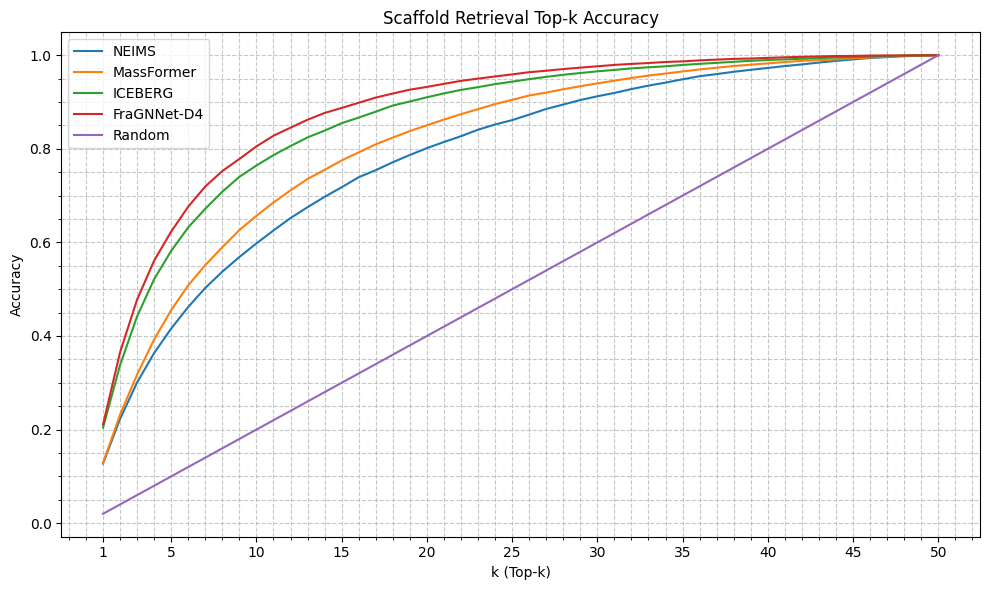

In [9]:
# Example data: x-axis (k values) and y-axis (top-k scores)
# k_values = [1, 5, 10, 20, 50]
# method1_scores = [0.70, 0.75, 0.80, 0.85, 0.90] #[0.9, 0.85, 0.8, 0.75, 0.7]
# method2_scores = [0.72, 0.78, 0.82, 0.87, 0.92] #[0.92, 0.87, 0.82, 0.78, 0.72]
# method3_scores = [0.68, 0.73, 0.78, 0.83, 0.88] #[0.88, 0.83, 0.78, 0.73, 0.68]
# all_method_scores = [method1_scores, method2_scores, method3_scores]
# all_method_labels = ['Method 1', 'Method 2', 'Method 3']

k_values = ks
all_method_scores = [scaffold_topk_df[scaffold_topk_df["model"] == model].values[0,:-1] for model in models+["random"]]
all_method_labels = [model_to_label[model] for model in models] + ["Random"]

plot_top_k_accuracy(
    k_values=k_values,
    all_method_scores=all_method_scores,
    all_method_labels=all_method_labels,
    title="Scaffold Retrieval Top-k Accuracy"
)

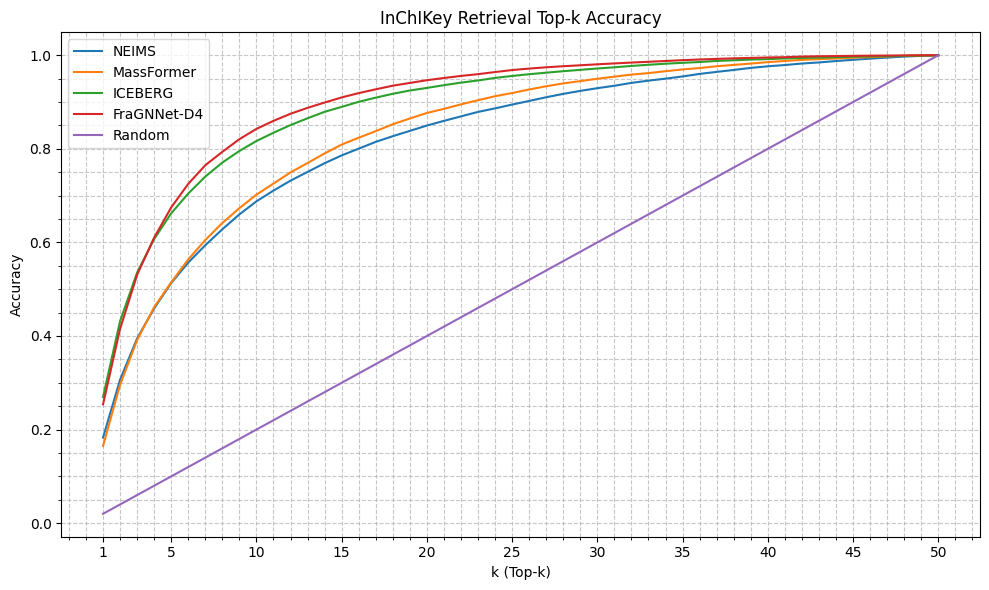

In [10]:
k_values = ks
all_method_scores = [inchikey_topk_df[inchikey_topk_df["model"] == model].values[0,:-1] for model in models+["random"]]
all_method_labels = [model_to_label[model] for model in models] + ["Random"]

plot_top_k_accuracy(
    k_values=k_values,
    all_method_scores=all_method_scores,
    all_method_labels=all_method_labels,
    title="InChIKey Retrieval Top-k Accuracy"
)

In [11]:
inchikey_summary_fp = os.path.join(inchikey_dp, "overall_stats_summary.csv")
scaffold_summary_fp = os.path.join(scaffold_dp, "overall_stats_summary.csv")

In [12]:
scaffold_summary_df = pd.read_csv(scaffold_summary_fp)
# remove seed info
scaffold_summary_df["model"] = scaffold_summary_df["model"].str[:-3]
# select correct ranking method
scaffold_summary_df = scaffold_summary_df[scaffold_summary_df["ranking method"] == scaffold_summary_df["model"].map(model_to_metric)].drop(columns=["ranking method"])
# average over seeds
scaffold_summary_df = scaffold_summary_df.groupby("model").mean().reset_index()
# remove unnecessary columns
scaffold_summary_df = scaffold_summary_df.drop(columns=["top-1", "top-3", "top-5", "top-10", "ans_score_mean", "ans_score_std"])
display(scaffold_summary_df)

,model,top-1 ratio,top-3 ratio,top-5 ratio,top-10 ratio,rank_mean,rank_std,rank_median,top_1_tanimoto_mean,top_1_tanimoto_std,ndcg_linear_mean,ndcg_linear_std,ndcg_exp_mean,ndcg_exp_std
0,fraggnn_d4_long,0.210655,0.477941,0.623346,0.805268,6.683927,7.640773,4.0,0.554747,0.273237,0.908545,0.056999,0.886494,0.069644
1,iceberg_inten3_100_long,0.204071,0.442203,0.581981,0.764382,7.624005,8.651507,4.0,0.549108,0.270746,0.904360,0.057573,0.881396,0.070222
2,massformer_long,0.128704,0.317869,0.455492,0.656869,10.104520,10.034872,6.4,0.475361,0.248759,0.886715,0.062120,0.859628,0.074350
3,neims_long,0.127387,0.300808,0.415983,0.597965,11.609787,11.200879,7.2,0.473826,0.248624,0.882423,0.063509,0.854406,0.076092


In [13]:
inchikey_summary_df = pd.read_csv(inchikey_summary_fp)
# remove seed info
inchikey_summary_df["model"] = inchikey_summary_df["model"].str[:-3]
# select correct ranking method
inchikey_summary_df = inchikey_summary_df[inchikey_summary_df["ranking method"] == inchikey_summary_df["model"].map(model_to_metric)].drop(columns=["ranking method"])
# average over seeds
inchikey_summary_df = inchikey_summary_df.groupby("model").mean().reset_index()
# remove unnecessary columns
inchikey_summary_df = inchikey_summary_df.drop(columns=["top-1", "top-3", "top-5", "top-10", "ans_score_mean", "ans_score_std"])
display(inchikey_summary_df)

,model,top-1 ratio,top-3 ratio,top-5 ratio,top-10 ratio,rank_mean,rank_std,rank_median,top_1_tanimoto_mean,top_1_tanimoto_std,ndcg_linear_mean,ndcg_linear_std,ndcg_exp_mean,ndcg_exp_std
0,fraggnn_d4_long,0.253895,0.530760,0.674781,0.842624,5.904381,7.120805,3.0,0.597122,0.274589,0.918766,0.053014,0.898905,0.065482
1,iceberg_inten3_100_long,0.269713,0.535638,0.662231,0.816718,6.392801,8.030049,3.0,0.607189,0.279243,0.917421,0.053851,0.897454,0.066532
2,massformer_long,0.164954,0.391333,0.514753,0.702060,9.018683,9.654221,5.0,0.517963,0.261565,0.898657,0.061502,0.874038,0.074176
3,neims_long,0.182951,0.394885,0.513142,0.687805,9.687734,10.703504,5.0,0.535189,0.266996,0.899847,0.062082,0.875490,0.075212


In [14]:
def plot_rank_histograms(k_values, all_method_histograms, all_method_labels,
                             title="Distribution over Predicted Rank of the Correct Candidate",
                             xlabel="Predicted Rank", ylabel="Fraction of Queries",
                             figsize=(10, 6), alpha=0.5):
    """
    Plot precomputed histograms (fractions per k) for multiple models as side-by-side bar charts.
    
    Parameters:
    - k_values: list or array
        Sorted list of rank values (e.g., [1, 2, 3, ..., k_max]).
    - all_method_histograms: list of lists
        Each sub-list contains the fraction of queries at each k for one model.
    - all_method_labels: list of str
        Labels corresponding to each model's histogram.
    - title: str
        The title of the plot.
    - xlabel: str
        Label for the x-axis.
    - ylabel: str
        Label for the y-axis.
    - figsize: tuple
        Figure size in inches.
    """
    # Ensure the lengths match
    if len(all_method_histograms) != len(all_method_labels):
        raise ValueError("Length of all_method_histograms and all_method_labels must match.")
    
    # Convert k_values to a numpy array for easy arithmetic
    k_values = np.array(k_values)
    n_models = len(all_method_histograms)
    
    # Determine bar width and offsets for side-by-side bars.
    total_width = 0.8  # total width reserved for all bars at one x location
    bar_width = total_width / n_models
    # Offsets to center the grouped bars at each k value
    offsets = np.linspace(-total_width/2 + bar_width/2, total_width/2 - bar_width/2, n_models)
    
    plt.figure(figsize=figsize)
    
    # Plot each model's histogram as a bar chart with an offset.
    for offset, hist, label in zip(offsets, all_method_histograms, all_method_labels):
        plt.bar(k_values + offset, hist, width=bar_width, alpha=alpha, label=label, edgecolor='black')
    
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.xticks(k_values)
    plt.legend()
    plt.show()

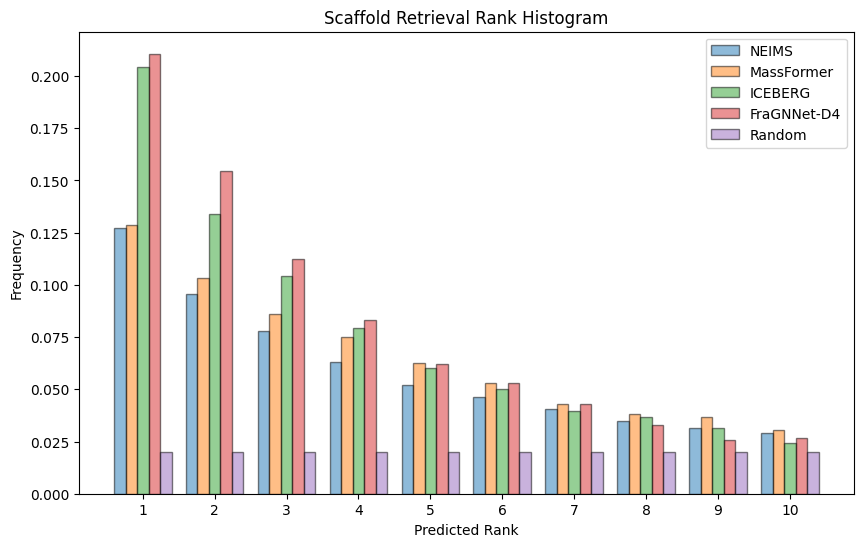

In [15]:
k_values = ks
all_method_scores = [scaffold_rank_df[scaffold_rank_df["model"] == model].values[0,:10] for model in models+["random"]]
all_method_labels = [model_to_label[model] for model in models] + ["Random"]

plot_rank_histograms(
    k_values=k_values[:10],
    all_method_histograms=all_method_scores,
    all_method_labels=all_method_labels,
    title="Scaffold Retrieval Rank Histogram",
    xlabel="Predicted Rank",
    ylabel="Frequency",
    figsize=(10, 6),
    alpha=0.5
)

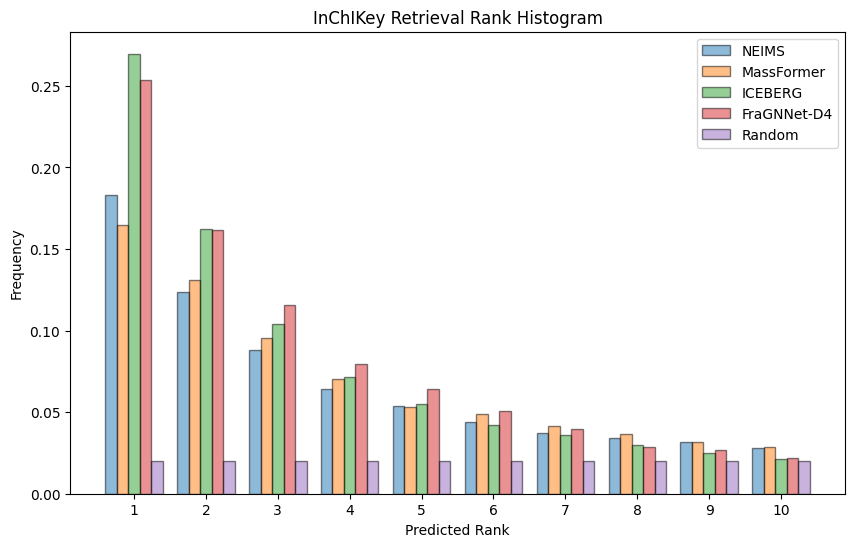

In [16]:
k_values = ks
all_method_scores = [inchikey_rank_df[inchikey_rank_df["model"] == model].values[0,:10] for model in models+["random"]]
all_method_labels = [model_to_label[model] for model in models] + ["Random"]

plot_rank_histograms(
    k_values=k_values[:10],
    all_method_histograms=all_method_scores,
    all_method_labels=all_method_labels,
    title="InChIKey Retrieval Rank Histogram",
    xlabel="Predicted Rank",
    ylabel="Frequency",
    figsize=(10, 6),
    alpha=0.5
)